In [3]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt

c:\Users\mayuu\anaconda3\envs\tron_rans\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
search_result = lk.search_lightcurve('Kepler-69',author='Kepler',cadence='long')
search_result , len(search_result)

(SearchResult containing 17 data products.
 
  #       mission      year author exptime  target_name  distance
                                      s                   arcsec 
 --- ----------------- ---- ------ ------- ------------- --------
   0 Kepler Quarter 01 2009 Kepler    1800 kplr008692861      0.0
   1 Kepler Quarter 02 2009 Kepler    1800 kplr008692861      0.0
   2 Kepler Quarter 03 2009 Kepler    1800 kplr008692861      0.0
   3 Kepler Quarter 04 2010 Kepler    1800 kplr008692861      0.0
   4 Kepler Quarter 05 2010 Kepler    1800 kplr008692861      0.0
   5 Kepler Quarter 06 2010 Kepler    1800 kplr008692861      0.0
   6 Kepler Quarter 07 2010 Kepler    1800 kplr008692861      0.0
   7 Kepler Quarter 08 2011 Kepler    1800 kplr008692861      0.0
   8 Kepler Quarter 09 2011 Kepler    1800 kplr008692861      0.0
   9 Kepler Quarter 10 2011 Kepler    1800 kplr008692861      0.0
  10 Kepler Quarter 11 2012 Kepler    1800 kplr008692861      0.0
  11 Kepler Quarter 12 2012 Kep

In [5]:
#ignore
#just testing the search result
row = search_result.table[1]
row['t_min'],row['t_max']
#this time is in MJD format(some astronomical standard time bs)
# from google - The Modified Julian Date (MJD) format is a simplified time and date system used in astronomy, spaceflight, and geodesy that counts the number of days since midnight on November 17, 1858

(np.float64(54964.01041666667), np.float64(56423.50069444445))

In [6]:
from astropy.time import Time


In [7]:
#ignore
start = Time(row['t_min'], format='mjd')
end = Time(row['t_max'], format='mjd')
start,end
# weird ahh output

(<Time object: scale='utc' format='mjd' value=54964.01041666667>,
 <Time object: scale='utc' format='mjd' value=56423.50069444445>)

In [8]:
#ignore
start.iso[:10], end.iso[:10]
#peak 

('2009-05-13', '2013-05-11')

In [9]:
#ignore
for i in range(len(search_result)):

    row = search_result.table[i]

    start = Time(row['t_min'], format='mjd')
    end = Time(row['t_max'], format='mjd')

    print(f"{row['mission']}: {start.iso[:10]} to {end.iso[:10]}")

# Im dropping this method cause its giving me some weird output that i dont really want , basically i want to find out whats the start and end time of each obs of the kepler telescope for this particular star, but this approach is giving me overall kepler obs time period 

Kepler Quarter 01: 2009-05-13 to 2013-05-11
Kepler Quarter 02: 2009-05-13 to 2013-05-11
Kepler Quarter 03: 2009-05-13 to 2013-05-11
Kepler Quarter 04: 2009-05-13 to 2013-05-11
Kepler Quarter 05: 2009-05-13 to 2013-05-11
Kepler Quarter 06: 2009-05-13 to 2013-05-11
Kepler Quarter 07: 2009-05-13 to 2013-05-11
Kepler Quarter 08: 2009-05-13 to 2013-05-11
Kepler Quarter 09: 2009-05-13 to 2013-05-11
Kepler Quarter 10: 2009-05-13 to 2013-05-11
Kepler Quarter 11: 2009-05-13 to 2013-05-11
Kepler Quarter 12: 2009-05-13 to 2013-05-11
Kepler Quarter 13: 2009-05-13 to 2013-05-11
Kepler Quarter 14: 2009-05-13 to 2013-05-11
Kepler Quarter 15: 2009-05-13 to 2013-05-11
Kepler Quarter 16: 2009-05-13 to 2013-05-11
Kepler Quarter 17: 2009-05-13 to 2013-05-11


In [10]:
#ignore
# approcah 2

lc = search_result[0].download()

print(lc)
#the standard used to represent time here is BJD - Barycentric Julian Date(no idea what ts means🙏)

       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
131.51216564080096  4.7264848e+04 ... -5.5481782e-03 -1.0210739e-02
131.53260016850982  4.7260516e+04 ... -5.5080131e-03 -1.0215473e-02
 131.5530345962252  4.7277145e+04 ... -5.6349826e-03 -1.0369956e-02
 131.5734689238161  4.7263336e+04 ... -5.6952755e-03 -1.0449667e-02
131.59390335141507  4.7272289e+04 ... -5.0795819e-03 -1.0367759e-02
131.61433787889837  4.7266520e+04 ... -5.1339036e-03 -1.0268716e-02
131.63477220638015  4.7264957e+04 ... -5.1393225e-03 -1.0189160e-02
 131.6552066338554  4.7270273e+04 ... -4.9518966e-03 -1.0071934e-02
 131.6756411612223  4.7269055e+04 ... -4.9845604e-03 -1.0139762e-02
               ...            ... ...            ...            ...
 164.7997175080818  4.7268070e+04 ...  2.6550307e-03  1.1370061e-02
164.82015174580738  4.7263660e+04 ...  2.6627562

In [11]:
lc_collection = search_result.download_all()

print(lc_collection)



LightCurveCollection of 17 objects:
    0: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=1 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    1: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=2 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    2: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    3: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=4 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    4: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=5 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    5: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=6 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    6: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=7 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    7: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=8 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    8: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=9 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    9: <KeplerLightCurve LABEL="KIC 8692861" QUARTER=10 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    10: <KeplerLightCur

In [12]:
for i, lc in enumerate(lc_collection):

    start = lc.time.min()
    end = lc.time.max()
    print(f"Observation {i+1}" , end = ' ')

    print("Start date:", start.iso , end = ' ')
    print("End date:", end.iso)
#perfect now

Observation 1 Start date: 2009-05-13 00:17:31.111 End date: 2009-06-15 11:36:25.247
Observation 2 Start date: 2009-06-20 06:21:55.886 End date: 2009-09-16 23:13:26.310
Observation 3 Start date: 2009-09-18 17:23:50.169 End date: 2009-12-16 23:53:59.448
Observation 4 Start date: 2009-12-19 21:02:40.842 End date: 2010-03-19 16:51:58.931
Observation 5 Start date: 2010-03-20 23:45:48.112 End date: 2010-06-23 15:54:01.887
Observation 6 Start date: 2010-06-24 23:17:13.856 End date: 2010-09-22 19:07:08.254
Observation 7 Start date: 2010-09-23 16:12:19.310 End date: 2010-12-22 01:09:39.323
Observation 8 Start date: 2011-01-06 20:43:24.243 End date: 2011-03-14 20:16:19.155
Observation 9 Start date: 2011-03-21 00:22:42.094 End date: 2011-06-26 10:13:54.370
Observation 10 Start date: 2011-06-27 08:18:00.531 End date: 2011-09-28 18:26:52.835
Observation 11 Start date: 2011-09-29 17:00:17.605 End date: 2012-01-04 19:49:04.977
Observation 12 Start date: 2012-01-05 21:48:30.403 End date: 2012-03-28 12

<Figure size 1200x500 with 0 Axes>

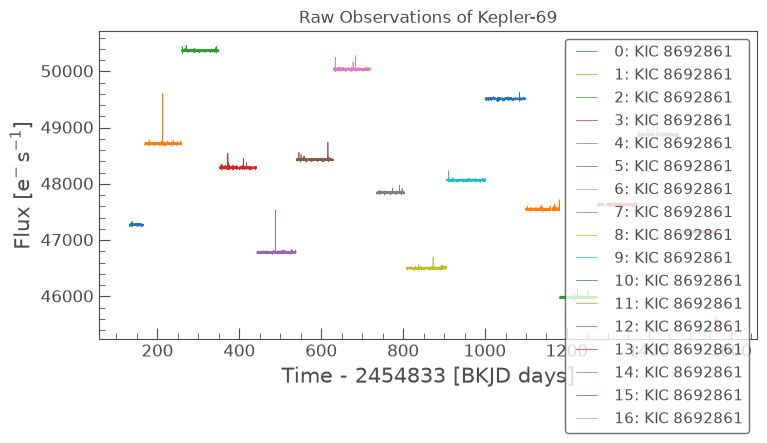

In [13]:
#raw data
plt.figure(figsize=(12, 5))

lc_collection.plot();

plt.title("Raw Observations of Kepler-69")
plt.show()

<Figure size 1200x500 with 0 Axes>

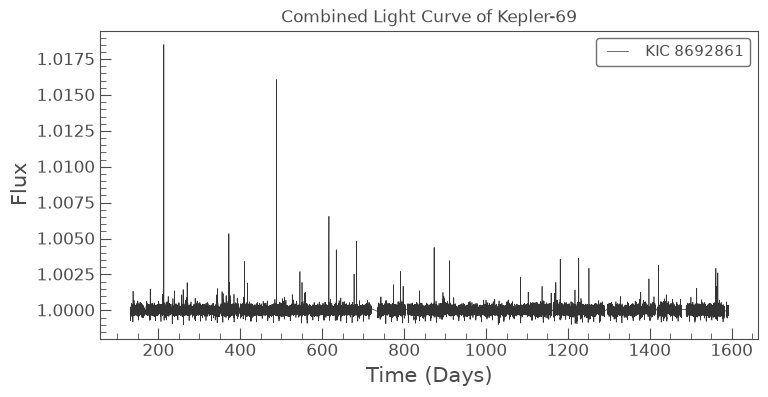

In [14]:
#after stitching and removing nans2
raw_lc = lc_collection.stitch()
raw_lc = raw_lc.remove_nans()
plt.figure(figsize=(12, 5))
raw_lc.plot()

plt.title("Combined Light Curve of Kepler-69")
plt.xlabel("Time (Days)")
plt.ylabel("Flux")
plt.show()


In [15]:
#removing outliers
clean_lc = raw_lc.remove_outliers(sigma=5)

print("Original stuff", len(raw_lc.time))
print("After i remove outliers:", len(clean_lc.time))
print( len(raw_lc.time) - len(clean_lc.time))

Original stuff 64793
After i remove outliers: 64713
80


In [16]:
# after flattening 
flat_lc, trend_lc = clean_lc.flatten(window_length=901,return_trend=True)

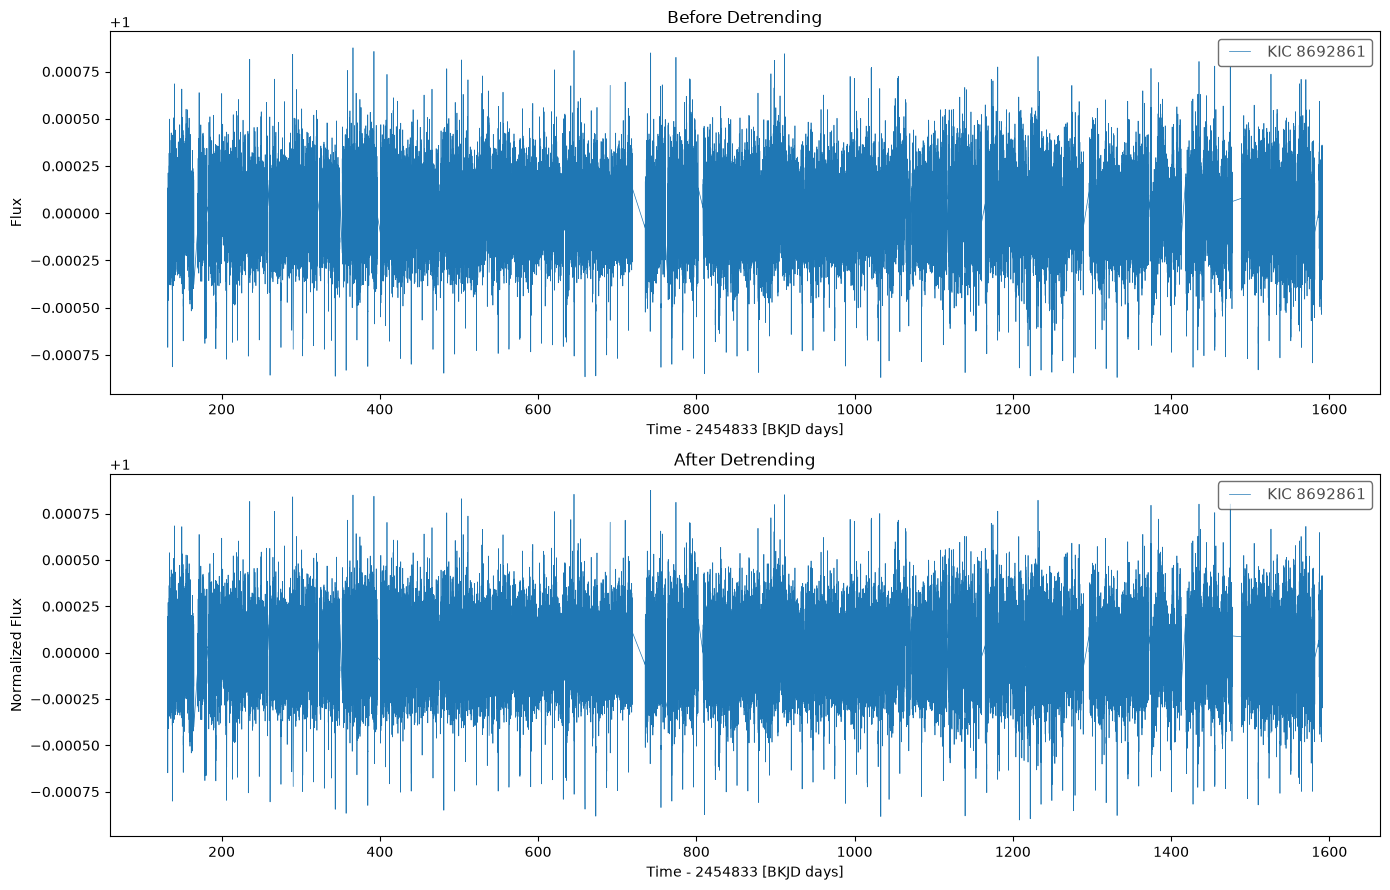

In [17]:
#comparing 

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
clean_lc.plot(ax=axes[0])
axes[0].set_title("Before Detrending")
axes[0].set_ylabel("Flux")
flat_lc.plot(ax=axes[1])
axes[1].set_title("After Detrending")
axes[1].set_ylabel("Normalized Flux")
plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

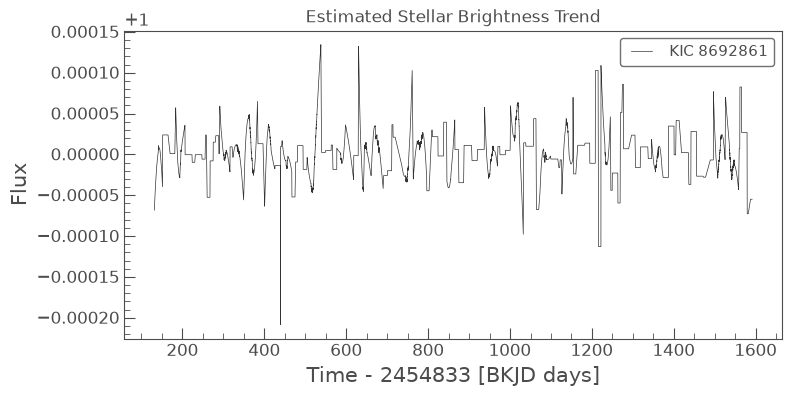

In [18]:
plt.figure(figsize=(14, 5))

trend_lc.plot()

plt.title("Estimated Stellar Brightness Trend")
plt.ylabel("Flux")
plt.show()